<a href="https://colab.research.google.com/github/jashwanth-cse/DIGITAL-PAYMENT-INSIGHT/blob/main/Digital_Payment_Insight_EDA_and_Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Digital Payment Insight —  Notebook

This notebook turns the Kaggle **Behavioral Fraud Detection** training file into an assessment-ready workflow for **Use Case 13: Digital Payment Insight**. It creates a clean submission folder split by assessment round.

It generates:

- Five linked tables: `transactions.csv`, `customers.csv`, `devices.csv`, `merchants.csv`, and `alerts.csv`.
- **Round 2:** cleaned master dataset, engineered features, ranked selected features, data-quality report, and key visualizations.
- **Round 3:** an Excel workbook with source tables, analysis summaries, charts, formulas, and native PivotTable/PivotChart instructions.
- **Round 4:** a short PowerPoint business pitch and speaking notes.
- Supporting source tables, EDA summary CSVs, data dictionary, and methodology, grouped separately.

**Important integrity notes**

1. The Kaggle source has encoded numeric categories. This notebook labels them as codes; it does not guess what each code means.
2. The source timestamp is numeric and its reference point/unit is not confirmed by the supplied metadata. We keep it unchanged and create a *relative elapsed-hour bin only under the documented working assumption that timestamps are seconds*. This is not a real clock-hour or time-of-day analysis.
3. The downloaded source had no missing values or duplicate transaction IDs in your audit. To demonstrate the assessment's requested cleaning workflow, this notebook injects a small, reproducible set of synthetic data-quality issues into a **working copy only**. The downloaded original remains unchanged.
4. Customer region/tenure, device type, merchant IDs/regions, and operational review alerts are clearly marked as synthetic or derived. Synthetic alerts do not use the fraud label.
5. Treat IQR outliers as review candidates, not automatic errors. We flag them without deleting the values.

## 1. Setup and load the Kaggle training data

Run the notebook from top to bottom. If the competition files are not already cached, KaggleHub may ask you to authenticate and accept the competition rules.

In [2]:
%pip -q install xlsxwriter python-pptx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.8/472.8 kB 9.0 MB/s eta 0:00:00


In [3]:
from pathlib import Path
import json
import math
import shutil
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
rng = np.random.default_rng(SEED)

# Find the cached download first; download only if it is not available.
DATA_DIR = Path("/root/.cache/kagglehub/competitions/behavioral-fraud-detection")
if not (DATA_DIR / "train.csv").exists():
    import kagglehub
    DATA_DIR = Path(kagglehub.competition_download("behavioral-fraud-detection"))

TRAIN_PATH = DATA_DIR / "train.csv"
if not TRAIN_PATH.exists():
    matches = list(DATA_DIR.rglob("train.csv"))
    if not matches:
        raise FileNotFoundError(f"Could not find train.csv beneath {DATA_DIR}")
    TRAIN_PATH = matches[0]

OUTPUT_DIR = Path.cwd() / "Digital_Payment_Insight_Submission"
ROUND2_DIR = OUTPUT_DIR / "Round_2_EDA_and_Feature_Engineering"
ROUND3_DIR = OUTPUT_DIR / "Round_3_Excel_Analysis"
ROUND4_DIR = OUTPUT_DIR / "Round_4_Business_Insights_Pitch"
SUPPORT_DIR = OUTPUT_DIR / "Supporting_Data"
TABLES_DIR = SUPPORT_DIR / "Related_Tables"
SUMMARY_DIR = SUPPORT_DIR / "EDA_Summary_CSVs"
REFERENCE_DIR = SUPPORT_DIR / "Reference_and_Methodology"
CHART_DIR = ROUND2_DIR / "Key_Visualizations"

for folder in [OUTPUT_DIR, ROUND2_DIR, ROUND3_DIR, ROUND4_DIR, SUPPORT_DIR,
               TABLES_DIR, SUMMARY_DIR, REFERENCE_DIR, CHART_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

source_df = pd.read_csv(TRAIN_PATH, low_memory=False)
required = {
    "transaction_id", "user_id", "timestamp", "amount",
    "merchant_category", "country", "device_id", "channel",
    "hours_since_prev_txn", "label"
}
missing_columns = required - set(source_df.columns)
if missing_columns:
    raise ValueError(f"Unexpected source schema. Missing columns: {sorted(missing_columns)}")

print("Source file:", TRAIN_PATH)
print("Source shape:", source_df.shape)
print("Columns:", source_df.columns.tolist())
print("Original missing cells:", int(source_df.isna().sum().sum()))
print("Original duplicate transaction IDs:", int(source_df["transaction_id"].duplicated().sum()))
print("Original fraud-label distribution:")
print(source_df["label"].value_counts(dropna=False).sort_index())

100%|██████████| 6.29M/6.29M [00:00<00:00, 61.5MB/s]

Extracting files...


Source file: /root/.cache/kagglehub/competitions/behavioral-fraud-detection/train.csv
Source shape: (182125, 10)
Columns: ['transaction_id', 'user_id', 'timestamp', 'amount', 'merchant_category', 'country', 'device_id', 'channel', 'hours_since_prev_txn', 'label']
Original missing cells: 0
Original duplicate transaction IDs: 0
Original fraud-label distribution:
label
0    179135
1      2990
Name: count, dtype: int64


## 2. Document the source and simulate the specified data-quality conditions

These controlled issues are added solely to the working copy so the notebook can demonstrate cleaning. They are not claimed to have existed in the original Kaggle files.

In [4]:
working = source_df.copy()

# Preserve the original numeric channel code, then create neutral code labels.
working["channel_code"] = pd.to_numeric(working["channel"], errors="coerce")
working["channel"] = working["channel_code"].map(
    lambda x: f"channel_{int(x)}" if pd.notna(x) else "unknown"
)

n_source = len(working)
n_missing_category = max(1, int(round(n_source * 0.005)))
n_missing_device = max(1, int(round(n_source * 0.003)))
n_inconsistent_channel = max(1, int(round(n_source * 0.005)))
n_duplicate_rows = max(1, int(round(n_source * 0.002)))

# Keep each corruption type reproducible.
cat_idx = rng.choice(working.index.to_numpy(), size=n_missing_category, replace=False)
dev_idx = rng.choice(working.index.to_numpy(), size=n_missing_device, replace=False)
channel_idx = rng.choice(working.index.to_numpy(), size=n_inconsistent_channel, replace=False)

working.loc[cat_idx, "merchant_category"] = np.nan
working.loc[dev_idx, "device_id"] = np.nan

for j, idx in enumerate(channel_idx):
    canonical = str(working.at[idx, "channel"])
    variants = [canonical.upper(), f" {canonical} ", canonical.title()]
    working.at[idx, "channel"] = variants[j % len(variants)]

# Append exact duplicate records to simulate duplicated transaction IDs.
duplicate_rows = working.sample(n=n_duplicate_rows, random_state=SEED).copy()
working_raw = pd.concat([working, duplicate_rows], ignore_index=True)

# IQR candidates are measured against the genuine source amounts (not injected).
source_amount = pd.to_numeric(source_df["amount"], errors="coerce")
q1_source, q3_source = source_amount.quantile([0.25, 0.75])
source_iqr = q3_source - q1_source
source_iqr_outliers = int(((source_amount < q1_source - 1.5 * source_iqr) |
                           (source_amount > q3_source + 1.5 * source_iqr)).sum())

pre_clean_metrics = {
    "Original source rows": len(source_df),
    "Working-copy rows before cleaning": len(working_raw),
    "Missing merchant category records": int(working_raw["merchant_category"].isna().sum()),
    "Duplicate transaction ID records": int(working_raw["transaction_id"].duplicated().sum()),
    "Distinct channel labels before normalization": int(working_raw["channel"].nunique(dropna=False)),
    "Missing device IDs": int(working_raw["device_id"].isna().sum()),
    "IQR outlier candidates in original source amounts": source_iqr_outliers,
}
print(pd.Series(pre_clean_metrics, name="value").to_string())

Original source rows                                 182125
Working-copy rows before cleaning                    182489
Missing merchant category records                       912
Duplicate transaction ID records                        364
Distinct channel labels before normalization              8
Missing device IDs                                      546
IQR outlier candidates in original source amounts     11278


## 3. Clean the working copy and engineer features

Cleaning choices: remove duplicate transaction IDs (keep the first original record), normalize channel labels, label missing merchant categories as `unknown`, retain missing device IDs with an explicit history-status flag, and flag amount outliers without deleting them. The source gap field is kept unchanged because its unit remains unverified.

In [5]:
clean = working_raw.drop_duplicates(subset=["transaction_id"], keep="first").copy()

# Standardize channel labels without assigning real-world meanings to numeric codes.
clean["channel"] = (
    clean["channel"].astype("string").str.strip().str.lower().str.replace(" ", "_", regex=False)
)
clean["channel"] = clean["channel"].fillna("unknown").astype(str)

# Keep the numeric source code as well as a readable, neutral category label.
merchant_cat_num = pd.to_numeric(clean["merchant_category"], errors="coerce")
clean["merchant_category_code"] = merchant_cat_num
clean["merchant_category"] = merchant_cat_num.map(
    lambda x: f"category_{int(x)}" if pd.notna(x) else "unknown"
)

clean["country_code"] = pd.to_numeric(clean["country"], errors="coerce")
clean = clean.drop(columns=["country"])

for col in ["timestamp", "amount", "hours_since_prev_txn", "user_id", "transaction_id", "device_id", "label"]:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

clean = clean.sort_values(["user_id", "timestamp", "transaction_id"]).reset_index(drop=True)

# Robust IQR outlier flag. Do not delete these rows automatically.
q1, q3 = clean["amount"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_iqr_bound = q1 - 1.5 * iqr
upper_iqr_bound = q3 + 1.5 * iqr
clean["amount_outlier_iqr_flag"] = (
    (clean["amount"] < lower_iqr_bound) | (clean["amount"] > upper_iqr_bound)
)
amount_q99 = clean["amount"].quantile(0.99)
clean["high_amount_q99_flag"] = clean["amount"] >= amount_q99

# The source field's name suggests hours, but its unit isn't confirmed.
# We use its numeric rank/quantile only and preserve the field unchanged.
positive_gaps = clean.loc[clean["hours_since_prev_txn"] > 0, "hours_since_prev_txn"]
short_gap_threshold = float(positive_gaps.quantile(0.05)) if len(positive_gaps) else np.nan
clean["short_supplied_gap_flag"] = (
    clean["hours_since_prev_txn"].notna()
    & (clean["hours_since_prev_txn"] > 0)
    & (clean["hours_since_prev_txn"] <= short_gap_threshold)
)

# Working assumption only: timestamps are seconds from an unspecified reference.
# This supports elapsed one-hour bins, not actual local clock time.
TIMESTAMP_UNIT_ASSUMPTION = "seconds (working assumption only; source reference time unknown)"
clean["elapsed_hour_index_assuming_seconds"] = np.floor(clean["timestamp"] / 3600).astype("Int64")

# Device novelty proxy: first observed occurrence of a user-device pair in this training file.
# This is not proof that a device was newly registered to the customer.
clean["new_device_flag"] = False
mask_device = clean["device_id"].notna()
first_seen_pair = ~clean.loc[mask_device].duplicated(subset=["user_id", "device_id"], keep="first")
clean.loc[mask_device, "new_device_flag"] = first_seen_pair.to_numpy()
clean["device_history_status"] = np.where(
    clean["device_id"].isna(), "incomplete - device ID missing in working copy", "device ID observed"
)
clean["device_novelty"] = np.select(
    [clean["device_id"].isna(), clean["new_device_flag"]],
    ["Unknown - missing device", "First seen for user in training data"],
    default="Previously seen for user in training data"
)

print("Clean transaction shape:", clean.shape)
print("Duplicate transaction IDs after cleaning:", int(clean["transaction_id"].duplicated().sum()))
print("Missing merchant category labels after cleaning:", int(clean["merchant_category"].isna().sum()))
print("Rows labelled unknown merchant category:", int((clean["merchant_category"] == "unknown").sum()))
print("Missing device IDs retained and flagged:", int(clean["device_id"].isna().sum()))
print("Normalized channel values:", sorted(clean["channel"].dropna().unique().tolist()))
print("IQR outlier candidates retained:", int(clean["amount_outlier_iqr_flag"].sum()))

Clean transaction shape: (182125, 19)
Duplicate transaction IDs after cleaning: 0
Missing merchant category labels after cleaning: 0
Rows labelled unknown merchant category: 911
Missing device IDs retained and flagged: 546
Normalized channel values: ['channel_0', 'channel_1']
IQR outlier candidates retained: 11278


## 4. Build the five related tables and synthetic operational alerts

Customer segments are derived from observed transaction frequency. Customer region/tenure, device types, merchant identities/regions, and review alerts are synthetic supplements. Alert rules use transaction attributes only; the original fraud label is not used to create alerts.

In [6]:
rng_synth = np.random.default_rng(20261013)
synthetic_regions = ["Synthetic_Region_A", "Synthetic_Region_B", "Synthetic_Region_C", "Synthetic_Region_D"]

# ---- customers.csv: one row per user; segment derived from observed transaction frequency ----
customer_summary = clean.groupby("user_id", dropna=False).agg(
    transaction_count=("transaction_id", "count"),
    median_transaction_amount=("amount", "median"),
    mean_transaction_amount=("amount", "mean"),
    first_observed_timestamp=("timestamp", "min"),
    last_observed_timestamp=("timestamp", "max"),
).reset_index()

country_mode = clean.groupby("user_id")["country_code"].agg(
    lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan
).rename("dominant_transaction_country_code").reset_index()
customer_summary = customer_summary.merge(country_mode, on="user_id", how="left")
rank_pct = customer_summary["transaction_count"].rank(method="first", pct=True)
customer_summary["customer_segment"] = pd.cut(
    rank_pct,
    bins=[0, 1/3, 2/3, 1.000001],
    labels=["Low activity", "Medium activity", "High activity"],
    include_lowest=True,
).astype(str)
customer_summary["region"] = rng_synth.choice(synthetic_regions, size=len(customer_summary))
customer_summary["tenure_months"] = rng_synth.integers(1, 61, size=len(customer_summary))
customer_summary["region_is_synthetic"] = True
customer_summary["tenure_is_synthetic"] = True
customers = customer_summary.copy()

# ---- devices.csv: transaction-device event table, since novelty is transaction/user-specific ----
unique_device_ids = clean.loc[clean["device_id"].notna(), "device_id"].drop_duplicates().tolist()
device_types = ["smartphone (synthetic)", "computer (synthetic)", "tablet (synthetic)"]
device_type_map = {
    did: str(rng_synth.choice(device_types)) for did in unique_device_ids
}
clean["device_type"] = clean["device_id"].map(device_type_map).fillna("Unknown - device missing")
clean["device_type_is_synthetic"] = True

devices = clean[[
    "transaction_id", "user_id", "device_id", "device_type",
    "new_device_flag", "device_history_status", "device_type_is_synthetic"
]].copy()

# ---- merchants.csv: synthetic merchant records with consistent category and synthetic region ----
all_categories = sorted(clean["merchant_category"].astype(str).unique().tolist())
merchant_rows = []
merchant_pool = {}
merchant_counter = 1
MERCHANTS_PER_CATEGORY = 10
for category in all_categories:
    pool = []
    for _ in range(MERCHANTS_PER_CATEGORY):
        merchant_id = f"SYN_M{merchant_counter:05d}"
        merchant_counter += 1
        region = str(rng_synth.choice(synthetic_regions))
        merchant_rows.append({
            "merchant_id": merchant_id,
            "merchant_category": category,
            "region": region,
            "merchant_identity_is_synthetic": True,
            "region_is_synthetic": True,
        })
        pool.append(merchant_id)
    merchant_pool[category] = pool
merchants = pd.DataFrame(merchant_rows)
clean["merchant_id"] = [
    str(rng_synth.choice(merchant_pool[category])) for category in clean["merchant_category"].astype(str)
]

# ---- alerts.csv: synthetic review queue generated independently of fraud label ----
rule_columns = [
    "high_amount_q99_flag", "new_device_flag",
    "short_supplied_gap_flag", "device_id"
]
clean["missing_device_flag"] = clean["device_id"].isna()
clean["alert_score"] = (
    clean["high_amount_q99_flag"].astype(int)
    + clean["new_device_flag"].astype(int)
    + clean["short_supplied_gap_flag"].astype(int)
    + clean["missing_device_flag"].astype(int)
)
alert_mask = clean["alert_score"] >= 1
alert_source = clean.loc[alert_mask, [
    "transaction_id", "alert_score", "high_amount_q99_flag", "new_device_flag",
    "short_supplied_gap_flag", "missing_device_flag"
]].copy()

rule_names = {
    "high_amount_q99_flag": "High amount (at/above source 99th percentile)",
    "new_device_flag": "First-seen user-device pair in training data",
    "short_supplied_gap_flag": "Low-tail supplied previous-transaction gap",
    "missing_device_flag": "Incomplete device history",
}
def describe_alert(row):
    active = [label for col, label in rule_names.items() if bool(row[col])]
    return "Multiple signals" if len(active) > 1 else (active[0] if active else "No signal")

alert_source["reason_category"] = alert_source.apply(describe_alert, axis=1)
alert_source["review_status"] = np.where(
    alert_source["alert_score"] >= 2,
    "Priority queue (simulated)",
    "Standard queue (simulated)"
)
alert_source["triggered_rules"] = alert_source.apply(
    lambda row: "; ".join(label for col, label in rule_names.items() if bool(row[col])), axis=1
)
alert_source["alert_source"] = "Synthetic rule-based alert; not a real operational review"
alert_source = alert_source.sort_values("transaction_id").reset_index(drop=True)
alert_source.insert(0, "alert_id", [f"SYN_A{i:06d}" for i in range(1, len(alert_source) + 1)])
alerts = alert_source[[
    "alert_id", "transaction_id", "review_status", "reason_category",
    "alert_score", "triggered_rules", "alert_source"
]].copy()

# ---- transactions.csv: source transaction facts plus transparent derived/synthetic links ----
transactions = clean.copy()

# ---- combined analytical table: join dimensions and alert queue ----
analysis = transactions.merge(
    customers[["user_id", "customer_segment", "region", "tenure_months", "dominant_transaction_country_code"]],
    on="user_id", how="left", validate="many_to_one"
).rename(columns={"region": "customer_region_synthetic"})
analysis = analysis.merge(
    merchants[["merchant_id", "region"]].rename(columns={"region": "merchant_region_synthetic"}),
    on="merchant_id", how="left", validate="many_to_one"
)
analysis = analysis.merge(
    alerts[["transaction_id", "alert_id", "review_status", "reason_category", "alert_score"]],
    on="transaction_id", how="left", validate="one_to_one"
)
analysis["is_alerted"] = analysis["alert_id"].notna()
analysis["review_status"] = analysis["review_status"].fillna("No simulated alert")
analysis["reason_category"] = analysis["reason_category"].fillna("No simulated alert")

# Data dictionary: distinguish source-derived, derived, and synthetic fields.
data_dictionary = pd.DataFrame([
    ["transaction_id", "Source", "Unique transaction identifier from the training file."],
    ["user_id", "Source", "User identifier from the training file."],
    ["timestamp", "Source; unit/reference unverified", "Preserved numeric timestamp. Do not interpret as a real date/time without metadata."],
    ["amount", "Source", "Transaction amount; IQR candidates are flagged, not deleted."],
    ["merchant_category_code", "Source", "Original encoded merchant-category code; no semantic mapping assumed."],
    ["merchant_category", "Normalized/cleaned", "Neutral label such as category_0; unknown marks injected missing values."],
    ["country_code", "Source; encoded", "Original numeric country code; do not infer country names without a mapping."],
    ["device_id", "Source, with controlled missingness in working copy", "Device identifier; missing values are retained and flagged."],
    ["channel_code", "Source", "Original numeric channel code."],
    ["channel", "Normalized/cleaned", "Neutral channel_0/channel_1 labels; no real-world channel names assumed."],
    ["hours_since_prev_txn", "Source; unit unverified", "Preserved unchanged; only relative numeric thresholds are used."],
    ["label", "Source training label", "Fraud label in training data; not used to generate synthetic alerts."],
    ["customer_segment", "Derived from source", "Low/medium/high activity segment based on observed transaction frequency."],
    ["region / tenure_months", "Synthetic", "Generated attributes for assessment completeness, not source facts."],
    ["device_type", "Synthetic", "Generated device class; not present in the source file."],
    ["new_device_flag", "Derived proxy", "First observed user-device pair in this training file, not proof of newly registered device."],
    ["merchant_id / merchant region", "Synthetic", "Generated merchant keys and regions, assigned consistently for joins."],
    ["alert_id / review_status / reason_category", "Synthetic rule-based", "Simulated review queue generated from transaction features only; not real manual review results."],
    ["elapsed_hour_index_assuming_seconds", "Derived working assumption", "timestamp // 3600; relative elapsed-hour bin only, not time-of-day."],
    ["amount_outlier_iqr_flag", "Derived from source amount", "Flags values outside 1.5×IQR fences; candidates for investigation, not automatic errors."],
], columns=["field_or_group", "provenance", "definition_and_interpretation"] )
data_dictionary.to_csv(REFERENCE_DIR / "data_dictionary.csv", index=False)

# Five required table files.
transactions.to_csv(TABLES_DIR / "transactions.csv", index=False)
customers.to_csv(TABLES_DIR / "customers.csv", index=False)
devices.to_csv(TABLES_DIR / "devices.csv", index=False)
merchants.to_csv(TABLES_DIR / "merchants.csv", index=False)
alerts.to_csv(TABLES_DIR / "alerts.csv", index=False)
analysis.to_csv(ROUND2_DIR / "cleaned_master_transactions.csv", index=False)

print("\nGenerated linked tables:")
for name, table in [
    ("transactions.csv", transactions), ("customers.csv", customers),
    ("devices.csv", devices), ("merchants.csv", merchants), ("alerts.csv", alerts),
]:
    print(f"{name:22s} {table.shape}")
print("cleaned_master_transactions.csv", analysis.shape)
print("Synthetic alerts:", len(alerts), f"({len(alerts)/len(transactions)*100:.2f}% of transactions)")


Generated linked tables:
transactions.csv       (182125, 24)
customers.csv          (5000, 12)
devices.csv            (182125, 7)
merchants.csv          (210, 5)
alerts.csv             (16706, 7)
cleaned_master_transactions.csv (182125, 34)
Synthetic alerts: 16706 (9.17% of transactions)


## 5. Data-quality report, EDA summaries, and engineered-feature review

In [7]:
# Quality report distinguishes source facts from deliberately injected working-copy conditions.
channel_source_n = int(source_df["channel"].nunique(dropna=False))
channel_raw_n = int(working_raw["channel"].nunique(dropna=False))
channel_clean_n = int(clean["channel"].nunique(dropna=False))
quality_report = pd.DataFrame([
    ["Training rows", len(source_df), len(working_raw), len(clean), "Duplicate rows were injected only into the working copy; duplicate IDs removed."],
    ["Missing merchant category records", int(source_df["merchant_category"].isna().sum()), int(working_raw["merchant_category"].isna().sum()), int(clean["merchant_category"].isna().sum()), "Missing working-copy category values labelled 'unknown'; source column retained as numeric code where available."],
    ["Duplicate transaction ID records", int(source_df["transaction_id"].duplicated().sum()), int(working_raw["transaction_id"].duplicated().sum()), int(clean["transaction_id"].duplicated().sum()), "Drop duplicate IDs, keeping the first record."],
    ["Distinct channel labels", channel_source_n, channel_raw_n, channel_clean_n, "Normalize case and whitespace; retain neutral channel_0/channel_1 names."],
    ["Missing device IDs", int(source_df["device_id"].isna().sum()), int(working_raw["device_id"].isna().sum()), int(clean["device_id"].isna().sum()), "Do not impute device identity; explicitly flag incomplete history."],
    ["IQR amount outlier candidates", source_iqr_outliers, int(clean["amount_outlier_iqr_flag"].sum()), int(clean["amount_outlier_iqr_flag"].sum()), "Preserve values and flag for review; outliers are not automatically errors."],
], columns=["metric", "original_source", "working_copy_before_cleaning", "cleaned_working_copy", "treatment"])
quality_report.to_csv(ROUND2_DIR / "data_quality_report.csv", index=False)

# EDA summaries.
amount_by_segment = analysis.groupby("customer_segment", observed=False).agg(
    transaction_count=("transaction_id", "count"),
    amount_mean=("amount", "mean"),
    amount_median=("amount", "median"),
    amount_q25=("amount", lambda s: s.quantile(0.25)),
    amount_q75=("amount", lambda s: s.quantile(0.75)),
    amount_q95=("amount", lambda s: s.quantile(0.95)),
    fraud_rate=("label", "mean"),
    alert_rate=("is_alerted", "mean"),
).reset_index()

hourly_volume = analysis.groupby("elapsed_hour_index_assuming_seconds", dropna=False).agg(
    transaction_count=("transaction_id", "count"),
    fraud_rate=("label", "mean"),
    alert_rate=("is_alerted", "mean"),
).reset_index().sort_values("elapsed_hour_index_assuming_seconds")

# Categorize missing device IDs separately; the other labels refer to first-seen proxies.
device_comparison = analysis.groupby("device_novelty", dropna=False).agg(
    transaction_count=("transaction_id", "count"),
    median_amount=("amount", "median"),
    fraud_rate=("label", "mean"),
    alert_rate=("is_alerted", "mean"),
).reset_index()

merchant_summary = analysis.groupby("merchant_category", dropna=False).agg(
    transaction_count=("transaction_id", "count"),
    median_amount=("amount", "median"),
    fraud_rate=("label", "mean"),
    alert_count=("is_alerted", "sum"),
    alert_rate=("is_alerted", "mean"),
).reset_index().sort_values("transaction_count", ascending=False)

country_summary = analysis.groupby("country_code", dropna=False).agg(
    transaction_count=("transaction_id", "count"),
    median_amount=("amount", "median"),
    fraud_rate=("label", "mean"),
    alert_count=("is_alerted", "sum"),
    alert_rate=("is_alerted", "mean"),
).reset_index().sort_values("transaction_count", ascending=False)
country_summary["country_code_label"] = country_summary["country_code"].map(
    lambda x: f"Code {int(x)}" if pd.notna(x) else "Unknown code"
)

alert_reason_summary = analysis.loc[analysis["is_alerted"]].groupby("reason_category", dropna=False).agg(
    alert_count=("transaction_id", "count"),
    fraud_rate_in_flagged_transactions=("label", "mean"),
    median_amount=("amount", "median"),
).reset_index().sort_values("alert_count", ascending=False)

channel_summary = analysis.groupby("channel", dropna=False).agg(
    transaction_count=("transaction_id", "count"),
    median_amount=("amount", "median"),
    fraud_rate=("label", "mean"),
    alert_rate=("is_alerted", "mean"),
).reset_index().sort_values("transaction_count", ascending=False)

for filename, frame in [
    ("amount_by_customer_segment.csv", amount_by_segment),
    ("volume_by_elapsed_hour.csv", hourly_volume),
    ("device_comparison.csv", device_comparison),
    ("merchant_category_summary.csv", merchant_summary),
    ("country_code_summary.csv", country_summary),
    ("alert_reason_summary.csv", alert_reason_summary),
    ("channel_summary.csv", channel_summary),
]:
    frame.to_csv(SUMMARY_DIR / filename, index=False)


# Export a transaction-level engineered-feature dataset for Round 2.
engineered_feature_columns = [
    "amount_outlier_iqr_flag", "high_amount_q99_flag",
    "short_supplied_gap_flag", "elapsed_hour_index_assuming_seconds",
    "new_device_flag", "device_history_status", "device_novelty",
    "device_type", "device_type_is_synthetic", "missing_device_flag",
    "alert_score", "customer_segment", "tenure_months",
    "customer_region_synthetic", "merchant_id", "merchant_region_synthetic",
    "dominant_transaction_country_code", "is_alerted", "review_status",
    "reason_category",
]
engineered_feature_columns = [c for c in engineered_feature_columns if c in analysis.columns]
engineered_features = analysis[["transaction_id", "user_id"] + engineered_feature_columns].copy()
engineered_features.to_csv(ROUND2_DIR / "engineered_features.csv", index=False)

# Purpose-aligned feature selection. Exclude identifiers and simulated alert outcomes;
# rank only transaction/customer-behaviour inputs against the source training label.
feature_notes = {
    "amount": ("Continuous", "Transaction magnitude; amount distribution and unusual-value screening."),
    "hours_since_prev_txn": ("Numeric source field; unit unverified", "Relative gap signal only; preserve original value."),
    "elapsed_hour_index_assuming_seconds": ("Derived numeric; assumption", "Relative elapsed-time grouping; not clock hour."),
    "merchant_category_code": ("Encoded categorical code", "Compare behaviour across merchant-category codes."),
    "country_code": ("Encoded categorical code", "Compare source country codes without guessing country names."),
    "channel_code": ("Encoded categorical code", "Compare behaviour across channel codes."),
    "amount_outlier_iqr_flag": ("Binary engineered", "Flags IQR candidates; does not delete high amounts."),
    "high_amount_q99_flag": ("Binary engineered", "Flags transactions at/above the 99th amount percentile."),
    "short_supplied_gap_flag": ("Binary engineered", "Low-tail supplied gap flag; time-gap units unverified."),
    "new_device_flag": ("Binary derived proxy", "First observed user-device pair in this training file."),
    "missing_device_flag": ("Binary data-quality flag", "Marks missing device identifiers in the working copy."),
    "customer_segment": ("Categorical derived", "Activity segment based on observed transaction frequency."),
    "device_novelty": ("Categorical derived", "Known/new-in-file/unknown device-history proxy."),
}
candidate_features = [c for c in feature_notes if c in analysis.columns]
feature_matrix = pd.DataFrame(index=analysis.index)
discrete_features = []
discrete_names = {
    "merchant_category_code", "country_code", "channel_code",
    "amount_outlier_iqr_flag", "high_amount_q99_flag",
    "short_supplied_gap_flag", "new_device_flag", "missing_device_flag",
    "customer_segment", "device_novelty",
}
for col in candidate_features:
    values = analysis[col]
    if col in discrete_names or values.dtype == "object" or str(values.dtype).startswith("string"):
        encoded, _ = pd.factorize(values.astype("string").fillna("__MISSING__"), sort=True)
        feature_matrix[col] = encoded.astype("int64")
        discrete_features.append(True)
    else:
        numeric = pd.to_numeric(values, errors="coerce").replace([np.inf, -np.inf], np.nan)
        median = numeric.median()
        feature_matrix[col] = numeric.fillna(0 if pd.isna(median) else median).astype(float)
        discrete_features.append(False)

selection_method = "Mutual information with source training label"
try:
    from sklearn.feature_selection import mutual_info_classif
    mi_scores = mutual_info_classif(
        feature_matrix.to_numpy(),
        analysis["label"].astype(int).to_numpy(),
        discrete_features=np.array(discrete_features, dtype=bool),
        random_state=SEED,
    )
except ImportError:
    # Keep the notebook runnable if scikit-learn is not installed.
    mi_scores = np.full(len(candidate_features), np.nan)
    selection_method = "Assessment-aligned judgement (scikit-learn unavailable)"

feature_selection_scores = pd.DataFrame({
    "feature_name": candidate_features,
    "selection_score": mi_scores,
    "feature_type": [feature_notes[c][0] for c in candidate_features],
    "assessment_use": [feature_notes[c][1] for c in candidate_features],
    "selection_method": selection_method,
    "score_interpretation": "Association score only; not evidence of causality or validated model performance.",
})
if feature_selection_scores["selection_score"].notna().any():
    feature_selection_scores = feature_selection_scores.sort_values("selection_score", ascending=False, na_position="last")
# Keep a focused shortlist of up to ten useful fields.
selected_features = feature_selection_scores.head(min(10, len(feature_selection_scores))).copy()
selected_features.insert(0, "selected_rank", range(1, len(selected_features) + 1))
selected_features.to_csv(ROUND2_DIR / "selected_features.csv", index=False)
feature_selection_scores.to_csv(SUMMARY_DIR / "feature_selection_scores.csv", index=False)

print("Round 2 evidence saved:")
print(" -", ROUND2_DIR / "cleaned_master_transactions.csv")
print(" -", ROUND2_DIR / "engineered_features.csv")
print(" -", ROUND2_DIR / "selected_features.csv")

print("\nAmount ranges by activity segment:")
print(amount_by_segment.round(4).to_string(index=False))
print("\nDevice comparison:")
print(device_comparison.round(4).to_string(index=False))
print("\nTop merchant categories by transaction volume:")
print(merchant_summary.head(10).round(4).to_string(index=False))
print("\nTop source country codes by transaction volume (codes are not decoded):")
print(country_summary.head(10).round(4).to_string(index=False))
print("\nSimulated alert reasons:")
print(alert_reason_summary.round(4).to_string(index=False))

Round 2 evidence saved:
 - /content/Digital_Payment_Insight_Submission/Round_2_EDA_and_Feature_Engineering/cleaned_master_transactions.csv
 - /content/Digital_Payment_Insight_Submission/Round_2_EDA_and_Feature_Engineering/engineered_features.csv
 - /content/Digital_Payment_Insight_Submission/Round_2_EDA_and_Feature_Engineering/selected_features.csv

Amount ranges by activity segment:
customer_segment  transaction_count  amount_mean  amount_median  amount_q25  amount_q75  amount_q95  fraud_rate  alert_rate
   High activity              71762      27.3977        19.9973     11.8971     33.8250     73.7179      0.0165      0.0894
    Low activity              49998      27.4495        20.0999     11.8192     34.2579     74.0984      0.0163      0.0964
 Medium activity              60365      27.0460        20.1027     12.0643     34.0094     71.2469      0.0164      0.0907

Device comparison:
                           device_novelty  transaction_count  median_amount  fraud_rate  alert_ra

## 6. Create and save the key visualizations

The hourly chart uses elapsed-hour bins under the timestamp-seconds working assumption. It must not be described as a real clock-hour or time-of-day chart until the timestamp reference and units are verified.

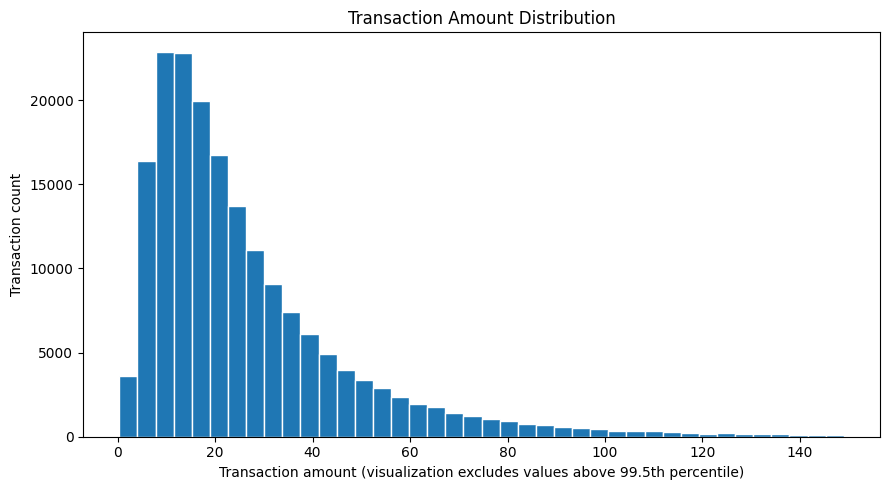

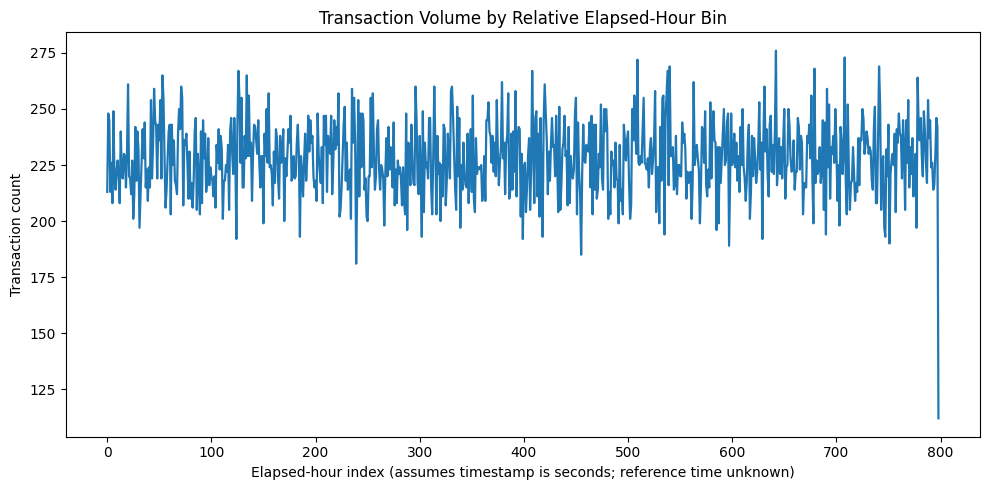

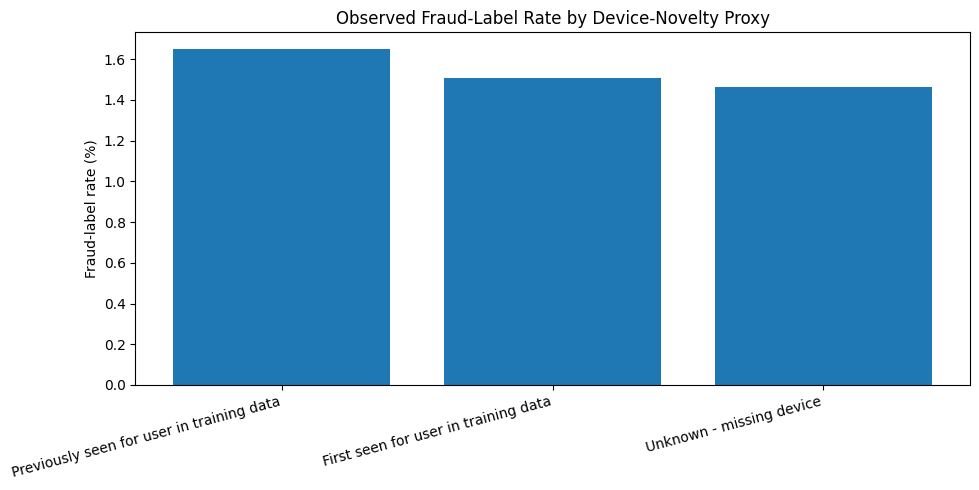

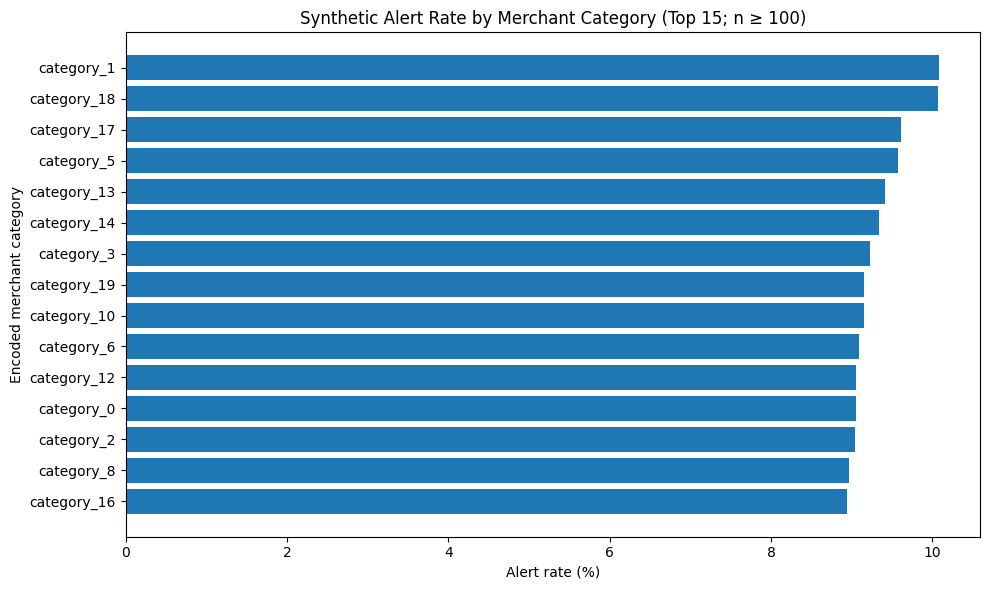

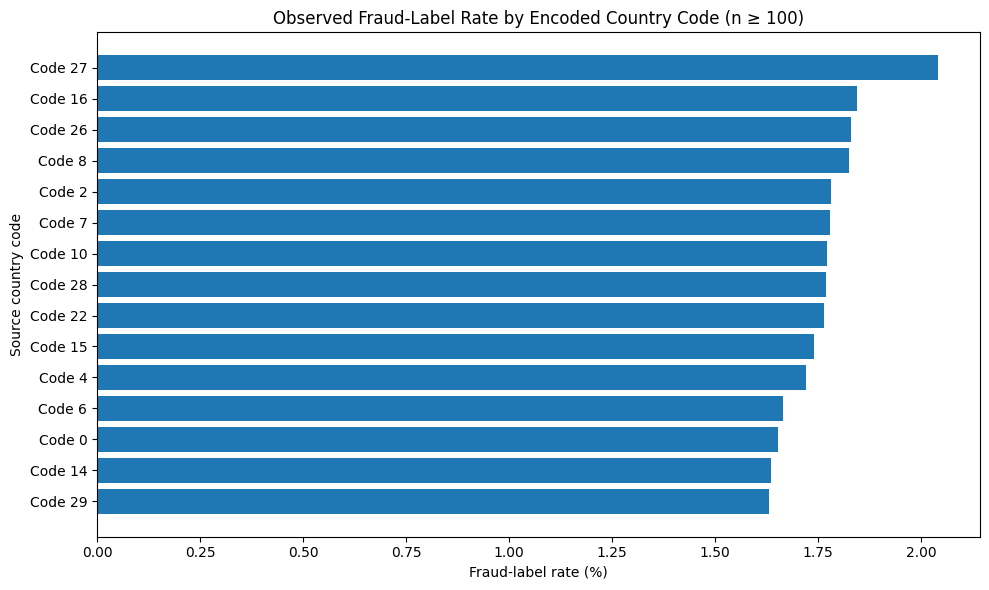

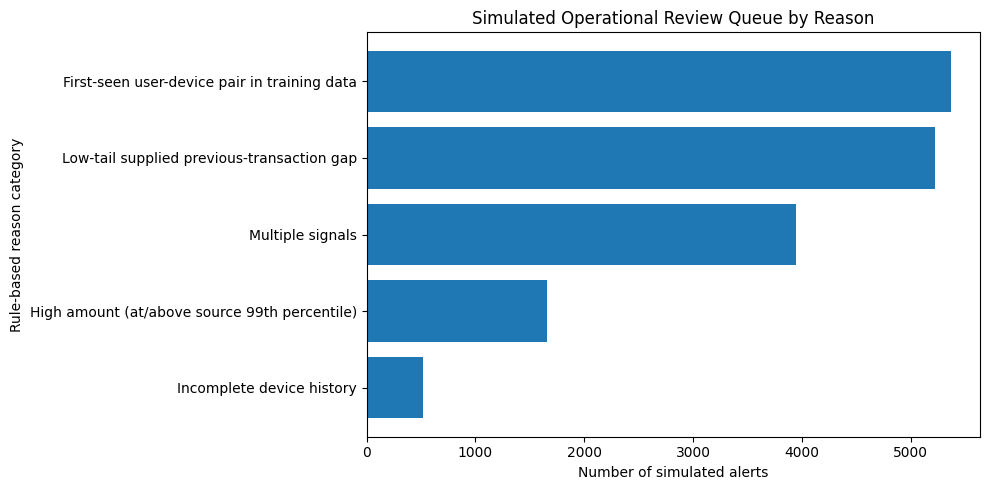

Saved charts to: /content/Digital_Payment_Insight_Submission/Round_2_EDA_and_Feature_Engineering/Key_Visualizations


In [8]:
# 1. Amount distribution (visualization capped at the 99.5th percentile only; data is unchanged).
amount_plot_cap = analysis["amount"].quantile(0.995)
plt.figure(figsize=(9, 5))
plt.hist(analysis.loc[analysis["amount"] <= amount_plot_cap, "amount"].dropna(), bins=40, edgecolor="white")
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction amount (visualization excludes values above 99.5th percentile)")
plt.ylabel("Transaction count")
plt.tight_layout()
plt.savefig(CHART_DIR / "amount_distribution.png", dpi=160)
plt.show()
plt.close()

# 2. Relative elapsed time; not actual hour of day.
plt.figure(figsize=(10, 5))
plt.plot(hourly_volume["elapsed_hour_index_assuming_seconds"], hourly_volume["transaction_count"], linewidth=1.6)
plt.title("Transaction Volume by Relative Elapsed-Hour Bin")
plt.xlabel("Elapsed-hour index (assumes timestamp is seconds; reference time unknown)")
plt.ylabel("Transaction count")
plt.tight_layout()
plt.savefig(CHART_DIR / "elapsed_hour_volume.png", dpi=160)
plt.show()
plt.close()

# 3. Device novelty proxy comparison.
device_plot = device_comparison.sort_values("transaction_count", ascending=False)
plt.figure(figsize=(10, 5))
plt.bar(device_plot["device_novelty"], device_plot["fraud_rate"] * 100)
plt.title("Observed Fraud-Label Rate by Device-Novelty Proxy")
plt.ylabel("Fraud-label rate (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(CHART_DIR / "device_comparison.png", dpi=160)
plt.show()
plt.close()

# 4. Merchant category alert rates, restricted to categories with at least 100 transactions.
merchant_plot = merchant_summary.loc[merchant_summary["transaction_count"] >= 100].sort_values("alert_rate", ascending=False).head(15)
plt.figure(figsize=(10, 6))
plt.barh(merchant_plot["merchant_category"].astype(str)[::-1], merchant_plot["alert_rate"][::-1] * 100)
plt.title("Synthetic Alert Rate by Merchant Category (Top 15; n ≥ 100)")
plt.xlabel("Alert rate (%)")
plt.ylabel("Encoded merchant category")
plt.tight_layout()
plt.savefig(CHART_DIR / "merchant_alert_rates.png", dpi=160)
plt.show()
plt.close()

# 5. Source country-code trends. Codes are kept encoded rather than guessed as named countries.
country_plot = country_summary.loc[country_summary["transaction_count"] >= 100].sort_values("fraud_rate", ascending=False).head(15)
plt.figure(figsize=(10, 6))
plt.barh(country_plot["country_code_label"].astype(str)[::-1], country_plot["fraud_rate"][::-1] * 100)
plt.title("Observed Fraud-Label Rate by Encoded Country Code (n ≥ 100)")
plt.xlabel("Fraud-label rate (%)")
plt.ylabel("Source country code")
plt.tight_layout()
plt.savefig(CHART_DIR / "country_code_fraud_rates.png", dpi=160)
plt.show()
plt.close()

# 6. Simulated alert reason counts.
reason_plot = alert_reason_summary.sort_values("alert_count", ascending=False)
plt.figure(figsize=(10, 5))
plt.barh(reason_plot["reason_category"].astype(str)[::-1], reason_plot["alert_count"][::-1])
plt.title("Simulated Operational Review Queue by Reason")
plt.xlabel("Number of simulated alerts")
plt.ylabel("Rule-based reason category")
plt.tight_layout()
plt.savefig(CHART_DIR / "alert_reasons.png", dpi=160)
plt.show()
plt.close()

print("Saved charts to:", CHART_DIR)